# Plotting the Data

This notebook has been designed to create some nice plots to explore the data. This will allow you to see what did you start with and what is the output now. 

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import xarray as xr


## function to find the root of the repository, which is assumed to contain a "data" directory
def find_repo_root() -> Path:
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "data").is_dir():
            return candidate
    raise FileNotFoundError("Could not find a repository containing data/")

### I am using Metref as the default variable to plot, but you can change it to any other variable in the dataset. 
def select_plot_variable(ds: xr.Dataset) -> str:
    preferred = ["METREF", "metref"]
    for name in preferred:
        if name in ds.data_vars:
            return name
    numeric = [name for name, da in ds.data_vars.items() if da.dtype.kind in "iuf"]
    if not numeric:
        raise ValueError("Dataset has no numeric data variable to plot")
    return numeric[0]

### This is for quick snapshot plotting - using time = 0, by default. You can change the time index to plot other time slices.
def plot_snapshot(ds: xr.Dataset, title: str):
    variable = select_plot_variable(ds)
    da = ds[variable]
    if "time" in da.dims:
        da = da.isel(time=0)
    print(f"{title}: plotting {variable}, shape={da.shape}")
    return da.plot(figsize=(10, 5), robust=True, cmap="viridis")


REPO_ROOT = find_repo_root()
DATA_ROOT = REPO_ROOT / "data"


## Raw NetCDF

Raw: NETCDF4_LSASAF_MSG_METREF_MSG-Disk_202006010000.nc: plotting METREF, shape=(3201, 3201)


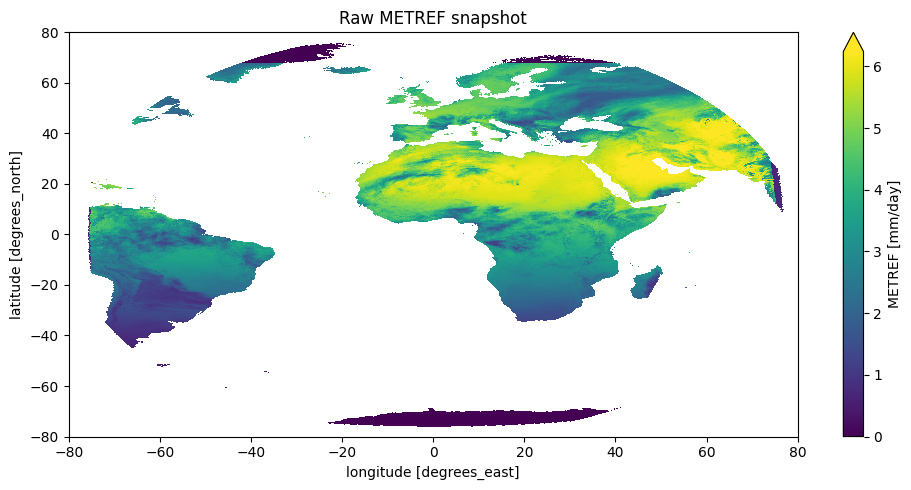

In [2]:
raw_files = sorted((DATA_ROOT / "raw").rglob("*.nc"))
## assert that we have at least one raw file to work with
assert raw_files, "No raw NetCDF files found"

raw_path = raw_files[0]
with xr.open_dataset(raw_path, decode_cf=True, mask_and_scale=True) as raw_ds:
    raw_ds.load()
    plot_snapshot(raw_ds, f"Raw: {raw_path.name}")
    # plt.gca().set_aspect("equal", adjustable="box") ## aspect ratio
    plt.tight_layout()
    plt.title("Raw METREF snapshot")
    plt.show()


## Interim NetCDF

Interim: NETCDF4_LSASAF_MSG_METREF_MSG-Disk_202006010000_processed.nc: plotting METREF, shape=(91, 121)


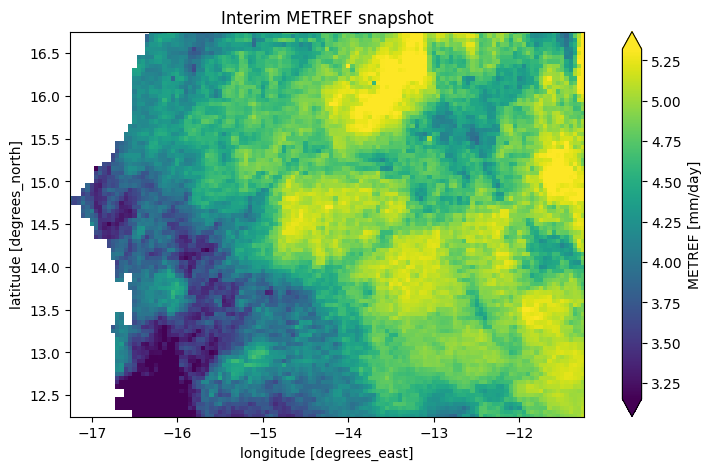

In [7]:
interim_files = sorted((DATA_ROOT / "interim").rglob("*.nc"))

assert interim_files, "No interim NetCDF files found"

interim_path = interim_files[0]

with xr.open_dataset(interim_path, decode_cf=True, mask_and_scale=True) as interim_ds:
    interim_ds.load()
    plot_snapshot(interim_ds, f"Interim: {interim_path.name}")
    plt.gca().set_aspect("equal", adjustable="box") ## aspect ratio
    extent = [interim_ds.lon.min(), interim_ds.lon.max(), interim_ds.lat.min(), interim_ds.lat.max()]
    plt.xlim(extent[0], extent[1])
    plt.ylim(extent[2], extent[3])
    # plt.tight_layout()
    plt.title("Interim METREF snapshot")
    plt.show()


## Zarr

Zarr: metref_sample_1month.zarr: plotting METREF, shape=(91, 121)


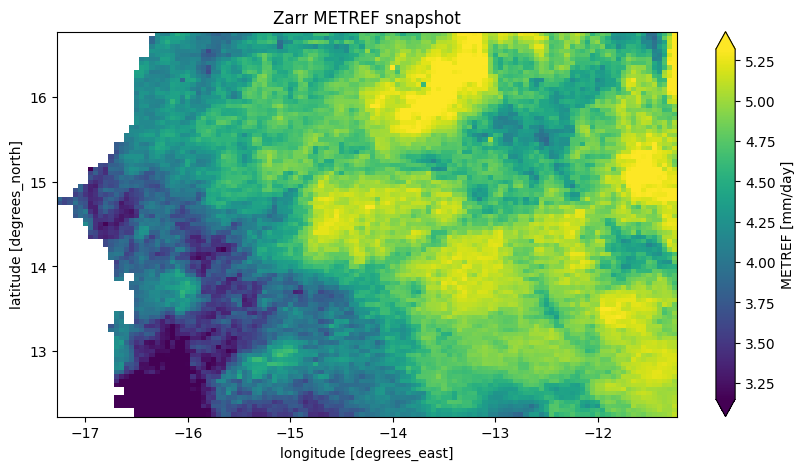

In [6]:
zarr_stores = sorted(
    path for path in (DATA_ROOT / "zarr").iterdir()
    if path.is_dir() and ((path / "zarr.json").exists() or (path / ".zgroup").exists())
)
assert zarr_stores, "No Zarr stores found"
zarr_path = zarr_stores[0]
with xr.open_zarr(zarr_path, consolidated=None) as zarr_ds:
    plot_snapshot(zarr_ds, f"Zarr: {zarr_path.name}")
    plt.title("Zarr METREF snapshot")
    plt.show()


## Raw versus interim versus Zarr means

/tmp/ipykernel_926059/1154902113.py:5: RuntimeWarning: Failed to open Zarr store with consolidated metadata, but successfully read with non-consolidated metadata. This is typically much slower for opening a dataset. To silence this warning, consider:
1. Consolidating metadata in this existing store with zarr.consolidate_metadata().
2. Explicitly setting consolidated=False, to avoid trying to read consolidate metadata, or
3. Explicitly setting consolidated=True, to raise an error in this case instead of falling back to try reading non-consolidated metadata.
  ds = xr.open_zarr(path, consolidated=None)


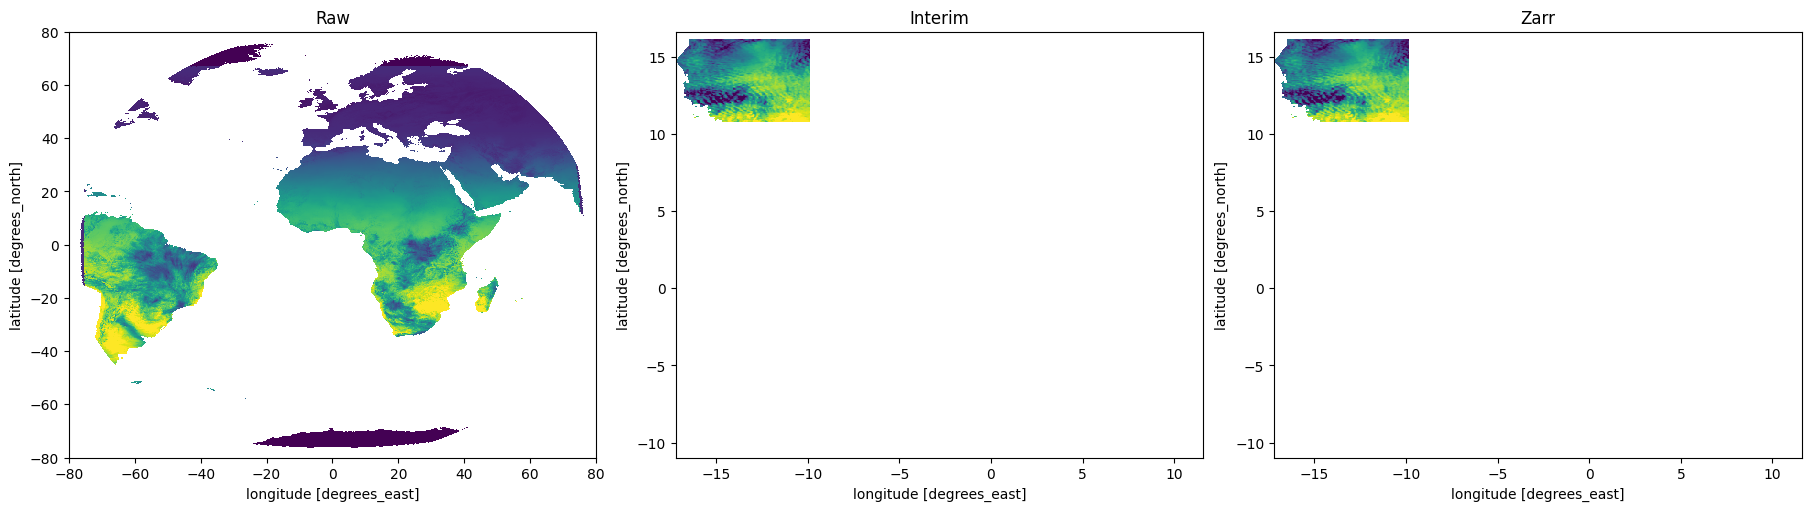

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), constrained_layout=True)
sources = [("Raw", raw_path), ("Interim", interim_path), ("Zarr", zarr_path)]
for axis, (label, path) in zip(axes, sources):
    if label == "Zarr":
        ds = xr.open_zarr(path, consolidated=None)
    else:
        ds = xr.open_dataset(path, decode_cf=True, mask_and_scale=True)
    try:
        variable = select_plot_variable(ds)
        da = ds[variable]
        if "time" in da.dims:
            da = da.isel(time=0)
        da.plot(ax=axis, robust=True, add_colorbar=False, cmap="viridis")
        axis.set_title(label)
    finally:
        ds.close()
plt.show()
